# Demonstration: Recurrence Labels, PrimeKG Fusion, and GNN Comparison

**Project:** Uncertainty-aware reasoning over patient-specific breast cancer graphs  
**Dataset:** TCGA Breast Invasive Carcinoma, PanCancer Atlas 2018  
**What this milestone adds:** A clean yes/no recurrence label, a join from each patient graph into the PrimeKG biomedical network, and a comparison of four models.  
**Best model on the imbalanced metric (AUPRC):** GraphSAGE, AUPRC 0.216 ± 0.054.

This notebook is written so it can be read top to bottom with a mentor. The plots below are the saved results of the 5-fold run. They are already embedded, so the figures are visible without re-training.

---

## 1. What we did, and why

The previous milestone built one small graph per patient: patient, tumour sample, and altered genes from a 500-gene panel. That graph records *what is altered*. It cannot yet say *whether the cancer came back*, and it cannot see that two different genes can sit on the same cancer pathway.

This milestone answers those two gaps:

1. **A target.** One binary label per patient, taken from clinical follow-up, and kept out of the graph so the model cannot cheat.
2. **A fused graph.** The patient's altered genes are linked to PrimeKG, a public map of proteins, pathways, drugs, and diseases.
3. **A comparison.** The same patients are scored by a plain table model and by three graph neural networks, using the same train/test splits.
4. **A readable path.** For a few patients the winning model predicted to recur, we write the actual graph path that carried that signal.

We did this because a mentor needs both a number and a reason. The number says whether the biomedical graph helps. The path says which gene, pathway, drug, or disease the model was looking at.


---

## 2. The target: what "recurrence" means here

We need one label per patient, `Y = 1` or `Y = 0`.

Breast cancer patients often live for many years even after the disease returns. Overall survival is therefore a slow, lagging label: many people who *did* recur are still alive at the end of the study, so "alive" does not mean "no recurrence."

The column we use is **PFS_STATUS** (progression-free survival status). In breast cancer benchmark papers this family of endpoints (PFS / PFI) is the usual choice, because it records whether the disease progressed during follow-up, and because almost every patient has a value.

| Clinical value | Our label | Plain meaning |
| --- | --- | --- |
| `1:PROGRESSION` | **Y = 1** | The cancer progressed or recurred during follow-up. |
| `0:CENSORED` | **Y = 0** | At the last visit, progression had **not** been recorded. Follow-up then stopped. |
| blank | dropped | One patient. We do not guess. |

### What "censored = 0" means

**Censored does not mean "cured."** It means the study stopped watching before an event was seen. The patient may have stayed well, or the cancer may have returned after the last visit. We only know they were free of recorded progression up to that date.

We do **not** give the model `PFS_MONTHS` (how long they were followed). A longer follow-up makes an event more likely to be observed, so using the time as a feature would leak the answer.

### Did we only use PFS?

**Yes, for the main experiment.** All four models are trained and compared on PFS only.

We also reran **only the winning model** on a second, stricter column, `NEW_TUMOR_EVENT_AFTER_INITIAL_TREATMENT` (Yes = 1, No = 0, blank dropped). That is a sensitivity check, not a second leaderboard. It has more missing values (199 patients dropped). Those results are reported separately and were not used to pick the winner.

Other outcome columns (overall survival, disease-specific survival, disease-free survival) stay in the raw file and are never used as inputs.

In the public file we actually trained on: **145 progressions, 938 censored, 1 missing** (1,084 patients in the study). An older local copy of this study counted 203 progressions. The rule is the same; the file vintage differs. Say that out loud if the mentor has the older count.


---

## 3. What an Entrez ID is, and why we need it

A gene has many names. `ERBB2`, `HER2`, and `NEU` are the same gene. A symbol can also be ambiguous.

**Entrez ID** is the stable integer assigned to that gene by NCBI, the US national gene database. TP53 is **7157**. PIK3CA is **5290**. ERBB2 is **2064**.

Our patient graphs already store that number on each gene node, for example `gene:TP53:7157`. PrimeKG stores the same NCBI number on its protein nodes. The fusion is a **1-to-1 join on that integer**. No fuzzy name matching. `5290.0` in the gene panel and `"5290"` in PrimeKG are treated as the same id.


---

## 4. Why fuse with PrimeKG, and how that graph reaches the GNN

### The problem without fusion

Patient A has an ERBB2 amplification. Patient B has a PIK3CA mutation. A spreadsheet model sees two unrelated columns. It has no reason to treat them as the same kind of growth signal.

### What PrimeKG adds

PrimeKG is a public biomedical network (proteins, pathways, drugs, diseases). We do not copy the whole network. We keep a small slice:

- **protein–protein** edges only when *both* proteins are in our 500-gene panel
- **pathway** edges for those genes (for example PI3K / Akt)
- **drug** edges for those genes (for example a drug that targets ERBB2)
- **disease** edges whose name contains "breast" or "mammary"

If a patient has an altered gene, we also keep the other panel genes that share that gene's pathway, even if the second gene is not altered in this patient. That is how ERBB2 and PIK3CA can meet on one pathway node.

We do **not** expand two hops through every protein in the human interactome. That would import most of PrimeKG and wash out the patient.

### How it is supplied to the neural nets

Each patient becomes one graph:

```text
Patient --has_sample--> Tumour sample --has_mutation / amplification / deletion--> Gene
Gene --protein_protein--> other panel gene
Gene --pathway_protein--> pathway
Gene --drug_protein--> drug
Gene --disease_protein--> breast disease
```

Every edge is also stored in reverse, so information can travel from a pathway back up to the patient.

Each node carries a numeric vector:

- **What kind of node** it is (patient, sample, gene, pathway, disease, drug)
- **Clinical context on the patient only:** age, sex, subtype, collapsed stage (I–IV), metastatic M stage
- **Alteration flags on the gene only:** mutated, high amplification, homozygous deletion, mutation count, known-driver flag
- **A learned id embedding** so the network can tell TP53 from PIK3CA. This is trained from scratch. We did not download BioBERT or TransE weights.

The label `Y` is stored beside the graph. It is not written onto any node.

The graph network passes messages along edges for three steps, then makes one score from the patient node plus a summary of the whole graph. A higher score means "more like progression."


---

## 5. The four models

All four see the **same patients**, the **same label**, and the **same clinical and alteration facts**. Only the graph models see PrimeKG edges. That is what makes the comparison fair.

| Model | In one sentence | Why it is here |
| --- | --- | --- |
| **MLP** | A normal neural net on a table: clinical fields plus a 500-gene yes/no alteration vector. No edges. | The baseline. If the graph models cannot beat this, PrimeKG is not helping. |
| **GCN** | Graph convolutional network. Each node is updated by an even average of its neighbours. | The simple graph baseline. Every neighbour counts the same. |
| **GATv2** | Graph attention network. The model learns a weight for each edge, so a driver alteration can count more than a weak link. | Tests whether *which* edge matters, not just that an edge exists. |
| **GraphSAGE** | Samples and aggregates a neighbourhood, and keeps the node's own features separate from the neighbours. | Handles patients whose graphs are denser or sparser than others. This is the model that won on AUPRC. |

### Why stratified 5-fold cross-validation

We do not train on everyone and then test on the same people. That would inflate the score.

**5-fold** means the 1,083 labeled patients are split into 5 groups. Each group takes a turn as the test set. The other four groups are used for training. Every patient is tested exactly once.

**Stratified** means each fold keeps about the same fraction of progressions (about 13%). A random split could put almost all of the rare progression cases into training and leave a test fold with almost none, which makes the score meaningless.

Inside each training fold we hold out a small validation slice to decide when to stop training, and to pick the probability cutoff used for the yes/no calls. The test patients are not used for either choice. Age is rescaled using only the training fold, so the test patients do not influence the scaling.


---

## 6. What AUROC and AUPRC mean, and whether higher is better

**Higher is better for both.** A useless model sits near 0.50 for AUROC. For AUPRC, a useless model sits near the prevalence, here about **0.13**, because only 13% of patients progress.

### AUROC (area under the ROC curve)

The ROC curve plots true-positive rate against false-positive rate as you slide the decision cutoff.

- **1.00** means perfect ranking: every patient who progressed is scored above every patient who was censored.
- **0.50** means the ranking is no better than chance.
- **Below 0.50** means the model is systematically backwards.

AUROC can look acceptable even when the positive class is rare, because the many censored patients dominate the curve.

### AUPRC (area under the precision-recall curve)

Precision is "of the patients we called progression, how many truly progressed?" Recall is "of the patients who truly progressed, how many did we catch?"

- **1.00** is perfect.
- The floor is the prevalence, about **0.13** here, not 0.50.
- This is the number we used to **pick the winner**, because recurrence is uncommon.

### The result

| Model | AUROC (higher better) | AUPRC (higher better) | Reading |
| --- | --- | --- | --- |
| MLP baseline | 0.550 ± 0.041 | 0.174 ± 0.021 | Slightly above chance. Best AUROC, by a small margin. |
| GCN | 0.541 ± 0.081 | 0.202 ± 0.073 | Similar to GraphSAGE on average, but the folds jump around. |
| GATv2 | 0.513 ± 0.044 | 0.153 ± 0.025 | Weakest. Attention did not beat the plain table. |
| **GraphSAGE** | **0.542 ± 0.051** | **0.216 ± 0.054** | **Best AUPRC.** Above the MLP (0.174) and above prevalence (0.13). |

The ± value is the spread across the five test folds. GraphSAGE's AUPRC spread (±0.054) still overlaps the MLP, so the gain is real but modest. This is a completed benchmark, not a clinical test.

Sensitivity check, GraphSAGE only, on new-tumour-event labels: AUROC 0.537 ± 0.084, AUPRC 0.158 ± 0.048.


In [1]:
# Saved 5-fold summary. Re-running this cell reprints the table; the figure below is already stored in the notebook.
from pathlib import Path
import pandas as pd
summary = pd.read_csv(Path("../outputs/gnn_benchmark/metrics_summary.csv"))
summary.round(3)


model        endpoint           AUROC          AUPRC
MLP          PFS (main)         0.550 ± 0.041  0.174 ± 0.021
GCN          PFS (main)         0.541 ± 0.081  0.202 ± 0.073
GATv2        PFS (main)         0.513 ± 0.044  0.153 ± 0.025
GraphSAGE    PFS (main)         0.542 ± 0.051  0.216 ± 0.054   <- best by AUPRC
GraphSAGE    new tumor event    0.537 ± 0.084  0.158 ± 0.048   (sensitivity only)


---

## 7. Plots

Bars are the mean across the five PFS folds, with the fold-to-fold spread drawn as error bars. ROC and precision-recall curves pool every patient from the fold in which that patient was held out.


### Comparison of AUROC and AUPRC

Blue is AUROC, orange is AUPRC. GraphSAGE has the tallest AUPRC bar. The MLP's AUROC bar is slightly taller than GraphSAGE. GATv2 is lowest on both.


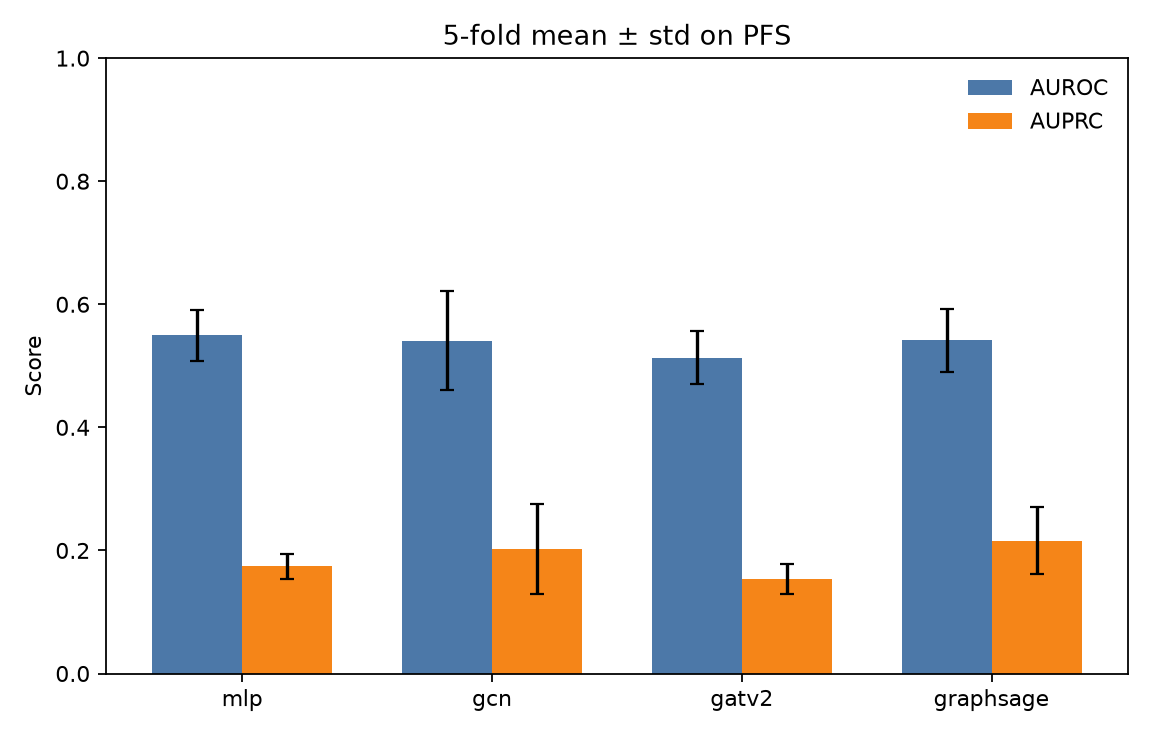

In [2]:
from IPython.display import Image
Image('../outputs/gnn_benchmark/comparison_bars.png')


### ROC curves

A curve that bends toward the top-left is better. All four curves are only a little above the dashed chance line. This matches AUROC values near 0.51–0.55.


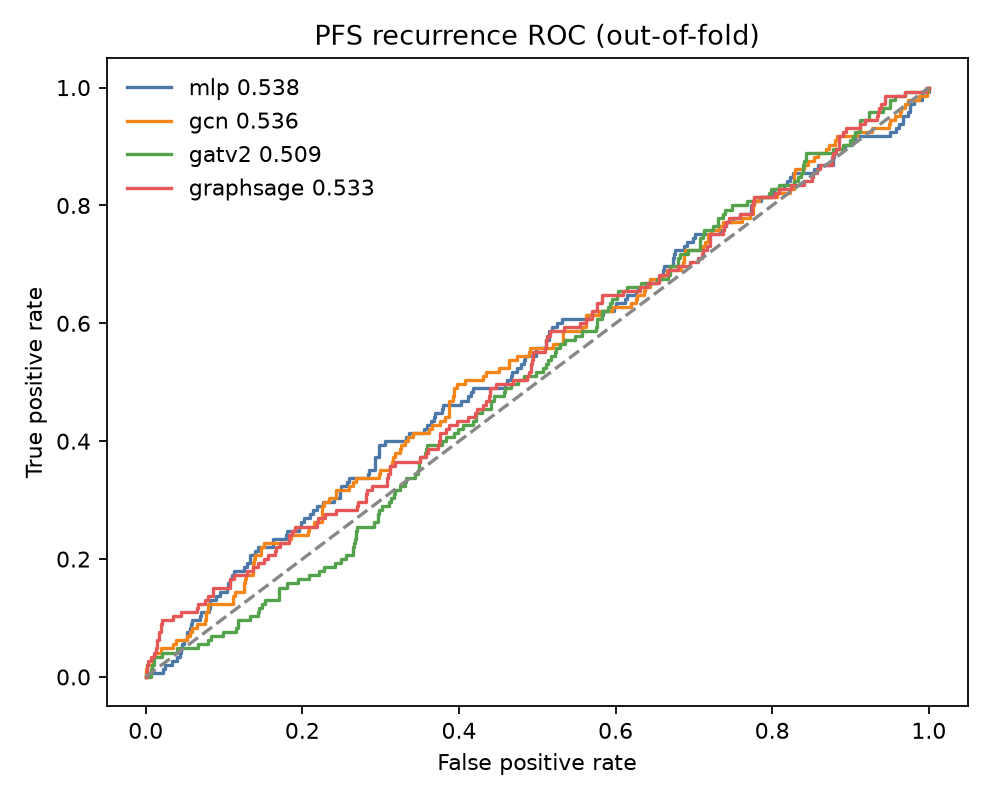

In [3]:
from IPython.display import Image
Image('../outputs/gnn_benchmark/roc_curves.png')


### Precision-recall curves

The dashed line is the prevalence (about 0.13). A useful model stays above that line. GraphSAGE (red) holds a higher precision at the same recall than the MLP (blue). This is the plot behind the model choice.


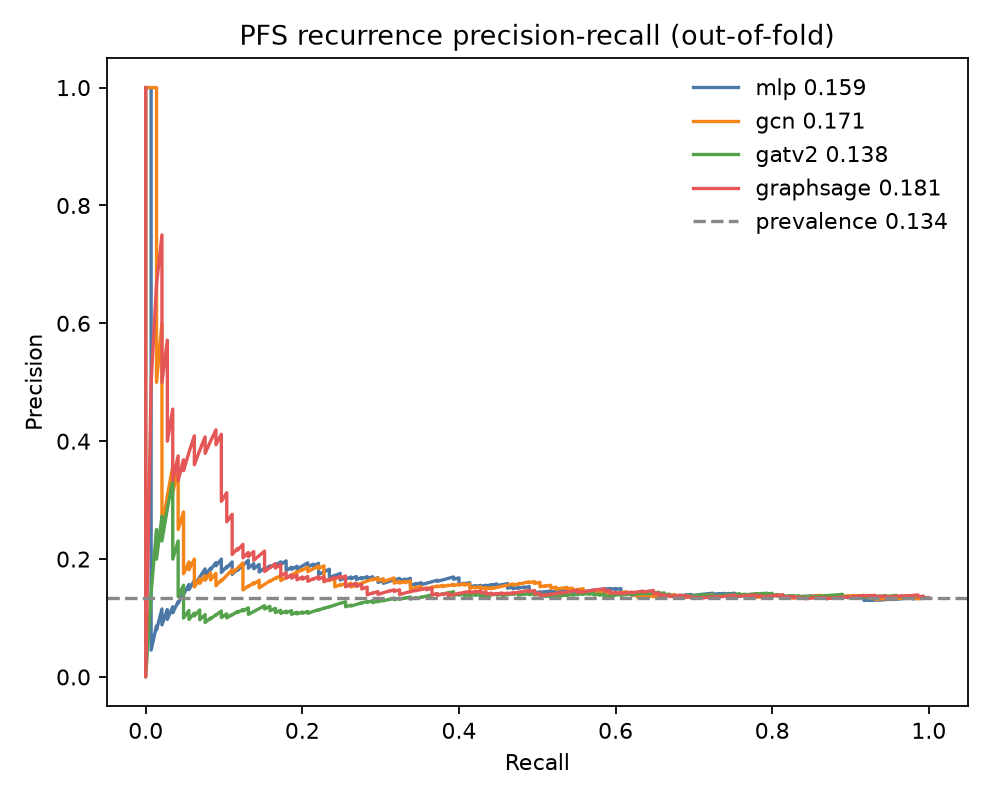

In [4]:
from IPython.display import Image
Image('../outputs/gnn_benchmark/pr_curves.png')


### Training loss

Loss falling means the model is fitting the training patients. We stop each fold when validation AUPRC stops improving, so a model is not trained until it memorizes the training set.


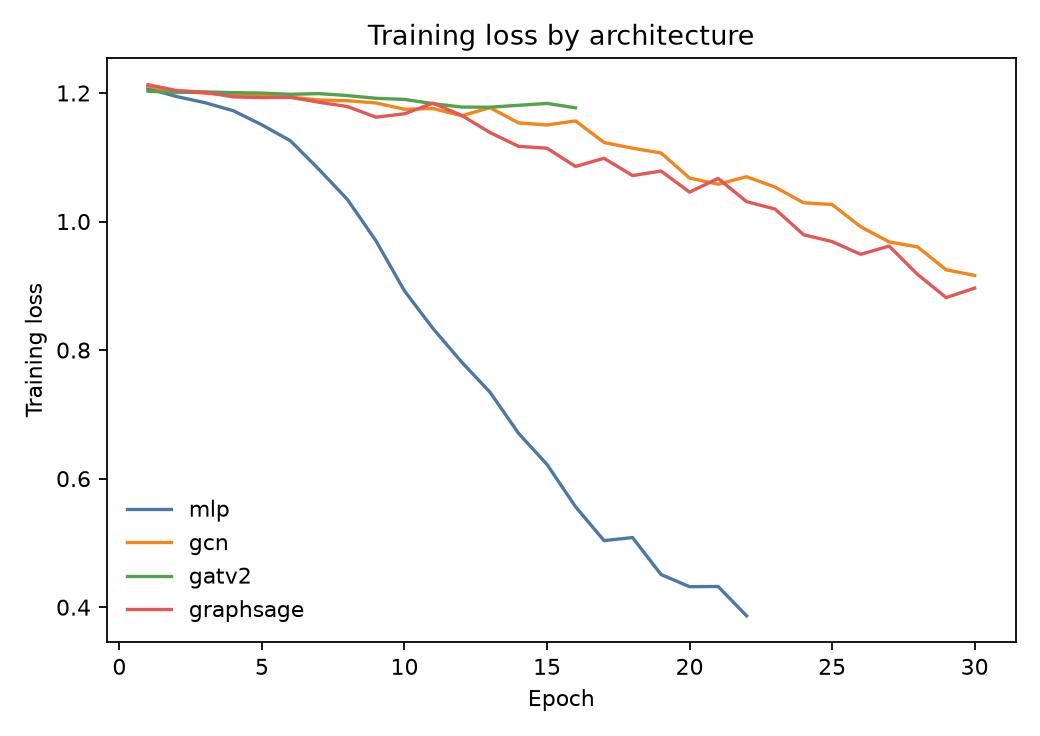

In [5]:
from IPython.display import Image
Image('../outputs/gnn_benchmark/loss_curves.png')


### GraphSAGE confusion matrix

Rows are the truth. Columns are the call made on held-out patients, using a cutoff chosen inside the training fold.

- 679 censored patients correctly left as non-progression
- 259 censored patients called progression (false alarms)
- 83 patients who progressed were missed
- 62 patients who progressed were caught

The model finds some events, and it also over-calls progression. That is why AUPRC stays well below 1.


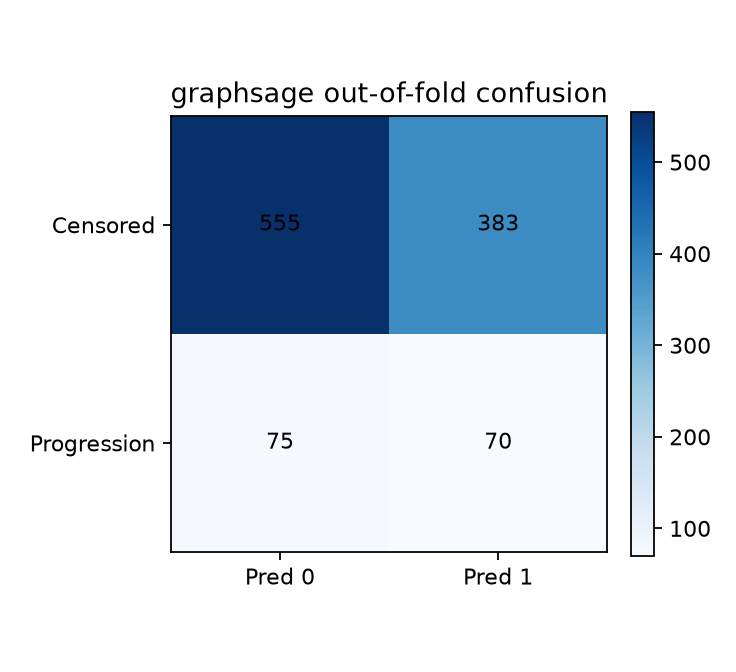

In [6]:
from IPython.display import Image
Image('../outputs/gnn_benchmark/confusion_matrix.png')


---

## 8. What a path explanation looks like

After GraphSAGE is trained, we ask which edges mattered for eight held-out patients who truly progressed and received a high score. We then write a short path that **already exists** in that patient's fused graph. We do not invent a drug-resistance story unless PrimeKG has that edge.

One real path from this run:

`patient TCGA-AO-A0J5 → sample → mutated PIK3CA (Entrez 5290) → pathway VEGFA-VEGFR2`

Read it as: this patient's sample carries a PIK3CA mutation, and PrimeKG places PIK3CA in that pathway. It is a trace of the graph, not a proven clinical cause.


In [7]:
from pathlib import Path
import pandas as pd
paths = pd.read_csv(Path("../outputs/gnn_benchmark/explanations.csv"))
paths[["patient_id", "y_true", "y_prob", "path_rank", "path"]].head(6)


patient_id   y_true  y_prob  path
TCGA-AO-A0J5  1       0.916   patient → sample → mutated PIK3CA (5290) → pathway VEGFA-VEGFR2
TCGA-AO-A0J5  1       0.916   patient → sample → mutated PIK3CA (5290) → pathway Regulation of signaling by CBL
TCGA-AO-A0J5  1       0.916   patient → sample → mutated GATA3 → protein RUNX1 → pathway RUNX1 interleukin signaling
TCGA-A2-A0SV  1       0.914   patient → sample → mutated KMT2C → pathway RUNX1 megakaryocyte differentiation


---

## 9. What to say to a mentor

The milestone is done: a leakage-safe PFS label, an Entrez join into PrimeKG, four models on the same stratified folds, plots, and traceable paths.

The scientific result is modest. GraphSAGE is the best model on AUPRC (0.216 versus 0.174 for the table baseline, versus about 0.13 for guessing the majority class). AUROC stays near 0.54 for both GraphSAGE and the MLP. The fused graph helps precision-recall a little. It does not yet separate recurrence cleanly enough to use as a clinical test.

Two data notes belong in the same sentence: this public clinical file has 145 PFS events, and the mutation table used for training is the cBioPortal mutation API extract, which is smaller than the original raw MAF.
